<a href="https://colab.research.google.com/github/IdreesMohamed/SMS-Spam-Detection/blob/main/SMS_Spam_Detection.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [2]:
import kagglehub

# Download latest version
path = kagglehub.dataset_download("vishakhdapat/sms-spam-detection-dataset")

print("Path to dataset files:", path)

Using Colab cache for faster access to the 'sms-spam-detection-dataset' dataset.
Path to dataset files: /kaggle/input/sms-spam-detection-dataset


In [3]:

!pip install -q tensorflow scikit-learn seaborn pandas matplotlib

import pandas as pd
import numpy as np
import re
import matplotlib.pyplot as plt
import seaborn as sns
import tensorflow as tf

from google.colab import files
from sklearn.model_selection import train_test_split
from sklearn.metrics import (
    accuracy_score, precision_score, recall_score,
    f1_score, confusion_matrix, classification_report
)
from tensorflow.keras.preprocessing.text import Tokenizer
from tensorflow.keras.preprocessing.sequence import pad_sequences
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import Embedding, LSTM, Dense, Dropout
from tensorflow.keras.callbacks import EarlyStopping

np.random.seed(42)
tf.random.set_seed(42)

print("Libraries imported successfully!")


Libraries imported successfully!


In [4]:

uploaded = files.upload()

filename = next(iter(uploaded))
df = pd.read_csv(filename, encoding="latin-1")

print("Dataset loaded successfully!")
print("Shape:", df.shape)
print("Columns:", df.columns.tolist())

display(df.head())


Saving spam_sms.csv to spam_sms.csv
Dataset loaded successfully!
Shape: (5572, 2)
Columns: ['v1', 'v2']


,v1,v2
0,ham,"Go until jurong point, crazy.. Available only ..."
1,ham,Ok lar... Joking wif u oni...
2,spam,Free entry in 2 a wkly comp to win FA Cup fina...
3,ham,U dun say so early hor... U c already then say...
4,ham,"Nah I don't think he goes to usf, he lives aro..."


In [5]:

# Automatically detect common column names
def find_column(columns, keywords):
    for col in columns:
        name = str(col).lower().strip()
        if any(word in name for word in keywords):
            return col
    return None

text_col = find_column(
    df.columns, ["message", "sms", "text", "v2", "content"]
)

label_col = find_column(
    df.columns, ["label", "category", "class", "target", "v1"]
)

# Fallback if column names are unfamiliar
if text_col is None:
    candidates = [
        c for c in df.columns if df[c].dtype == "object"
    ]
    text_col = max(
        candidates,
        key=lambda c: df[c].astype(str).str.len().mean()
    )

if label_col is None:
    candidates = [c for c in df.columns if c != text_col]
    label_col = min(candidates, key=lambda c: df[c].nunique())

df = df[[text_col, label_col]].copy()
df.columns = ["message", "label"]

# Remove missing values and duplicates
df.dropna(subset=["message", "label"], inplace=True)
df["message"] = df["message"].astype(str).str.strip()
df["label"] = df["label"].astype(str).str.strip().str.lower()

df = df[(df["message"] != "") & (df["label"] != "")]
df.drop_duplicates(subset=["message"], inplace=True)

# Convert labels into numbers
label_map = {
    "ham": 0,
    "spam": 1,
    "not spam": 0,
    "legitimate": 0,
    "legit": 0
}

df["label"] = df["label"].map(label_map)
df.dropna(subset=["label"], inplace=True)
df["label"] = df["label"].astype(int)

# Keep approximately 2,000 messages, preserving both classes
df = df.groupby("label", group_keys=False).apply(
    lambda group: group.sample(
        n=min(len(group), 1000), random_state=42
    )
)

df = df.sample(frac=1, random_state=42).reset_index(drop=True)

# Clean SMS text
def clean_text(text):
    text = text.lower()
    text = re.sub(r"http\S+|www\.\S+", " url ", text)
    text = re.sub(r"\S+@\S+", " email ", text)
    text = re.sub(r"[^a-z0-9\s]", " ", text)
    text = re.sub(r"\s+", " ", text).strip()
    return text

df["message"] = df["message"].apply(clean_text)

print("Cleaned dataset shape:", df.shape)
print("\nClass distribution:")
print(df["label"].value_counts().rename(
    index={0: "Ham", 1: "Spam"}
))
display(df.head())


Cleaned dataset shape: (1642, 2)

Class distribution:
label
Ham     1000
Spam     642
Name: count, dtype: int64


/tmp/ipykernel_1756/3827731765.py:56: DeprecationWarning: DataFrameGroupBy.apply operated on the grouping columns. This behavior is deprecated, and in a future version of pandas the grouping columns will be excluded from the operation. Either pass `include_groups=False` to exclude the groupings or explicitly select the grouping columns after groupby to silence this warning.
  df = df.groupby("label", group_keys=False).apply(


,message,label
0,well done and luv ya all,0
1,for ur chance to win a 250 cash every wk txt a...,1
2,of course i guess god s just got me on hold ri...,0
3,feel yourself that you are always happy slowly...,0
4,private your 2003 account statement for shows ...,1


In [6]:

X = df["message"].values
y = df["label"].values

X_train, X_test, y_train, y_test = train_test_split(
    X, y,
    test_size=0.20,
    random_state=42,
    stratify=y
)

print("Training messages:", len(X_train))
print("Testing messages:", len(X_test))


Training messages: 1313
Testing messages: 329


In [7]:

vocab_size = 5000
max_length = 100

tokenizer = Tokenizer(
    num_words=vocab_size,
    oov_token="<OOV>"
)

# Fit vocabulary only on training data
tokenizer.fit_on_texts(X_train)

X_train_seq = tokenizer.texts_to_sequences(X_train)
X_test_seq = tokenizer.texts_to_sequences(X_test)

X_train_pad = pad_sequences(
    X_train_seq,
    maxlen=max_length,
    padding="post",
    truncating="post"
)

X_test_pad = pad_sequences(
    X_test_seq,
    maxlen=max_length,
    padding="post",
    truncating="post"
)

print("Training shape:", X_train_pad.shape)
print("Testing shape:", X_test_pad.shape)


Training shape: (1313, 100)
Testing shape: (329, 100)


In [8]:

model = Sequential([
    Embedding(
        input_dim=vocab_size,
        output_dim=64,
        mask_zero=True
    ),
    LSTM(64),
    Dropout(0.3),
    Dense(32, activation="relu"),
    Dense(1, activation="sigmoid")
])

model.compile(
    optimizer="adam",
    loss="binary_crossentropy",
    metrics=["accuracy"]
)

model.build(input_shape=(None, max_length))
model.summary()


Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ embedding (Embedding)           │ (None, 100, 64)        │       320,000 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ lstm (LSTM)                     │ (None, 64)             │        33,024 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 64)             │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 32)             │         2,080 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 1)              │            33 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 355,137 (1.35 MB)

 Trainable params: 355,137 (1.35 MB)

 Non-trainable params: 0 (0.00 B)

In [9]:

early_stop = EarlyStopping(
    monitor="val_loss",
    patience=2,
    restore_best_weights=True
)

history = model.fit(
    X_train_pad,
    y_train,
    epochs=10,
    batch_size=32,
    validation_split=0.2,
    callbacks=[early_stop],
    verbose=1
)

print("Training completed!")


Epoch 1/10
33/33 ━━━━━━━━━━━━━━━━━━━━ 8s 117ms/step - accuracy: 0.7400 - loss: 0.6228 - val_accuracy: 0.9392 - val_loss: 0.3296
Epoch 2/10
33/33 ━━━━━━━━━━━━━━━━━━━━ 3s 81ms/step - accuracy: 0.9581 - loss: 0.2193 - val_accuracy: 0.9506 - val_loss: 0.1869
Epoch 3/10
33/33 ━━━━━━━━━━━━━━━━━━━━ 3s 81ms/step - accuracy: 0.9724 - loss: 0.1254 - val_accuracy: 0.9810 - val_loss: 0.0993
Epoch 4/10
33/33 ━━━━━━━━━━━━━━━━━━━━ 7s 135ms/step - accuracy: 0.9924 - loss: 0.0444 - val_accuracy: 0.9696 - val_loss: 0.1121
Epoch 5/10
33/33 ━━━━━━━━━━━━━━━━━━━━ 3s 85ms/step - accuracy: 0.9962 - loss: 0.0234 - val_accuracy: 0.9696 - val_loss: 0.0834
Epoch 6/10
33/33 ━━━━━━━━━━━━━━━━━━━━ 5s 89ms/step - accuracy: 0.9943 - loss: 0.0246 - val_accuracy: 0.9392 - val_loss: 0.1843
Epoch 7/10
33/33 ━━━━━━━━━━━━━━━━━━━━ 4s 109ms/step - accuracy: 1.0000 - loss: 0.0120 - val_accuracy: 0.9582 - val_loss: 0.1201
Training completed!


In [10]:

y_prob = model.predict(X_test_pad).ravel()
y_pred = (y_prob >= 0.5).astype(int)

print("MODEL EVALUATION")
print("----------------")
print(f"Accuracy : {accuracy_score(y_test, y_pred):.4f}")
print(f"Precision: {precision_score(y_test, y_pred, zero_division=0):.4f}")
print(f"Recall   : {recall_score(y_test, y_pred, zero_division=0):.4f}")
print(f"F1-score : {f1_score(y_test, y_pred, zero_division=0):.4f}")

print("\nClassification Report:")
print(classification_report(
    y_test, y_pred,
    labels=[0, 1],
    target_names=["Ham", "Spam"],
    zero_division=0
))


11/11 ━━━━━━━━━━━━━━━━━━━━ 2s 103ms/step
MODEL EVALUATION
----------------
Accuracy : 0.9787
Precision: 0.9552
Recall   : 0.9922
F1-score : 0.9734

Classification Report:
              precision    recall  f1-score   support

         Ham       0.99      0.97      0.98       200
        Spam       0.96      0.99      0.97       129

    accuracy                           0.98       329
   macro avg       0.98      0.98      0.98       329
weighted avg       0.98      0.98      0.98       329



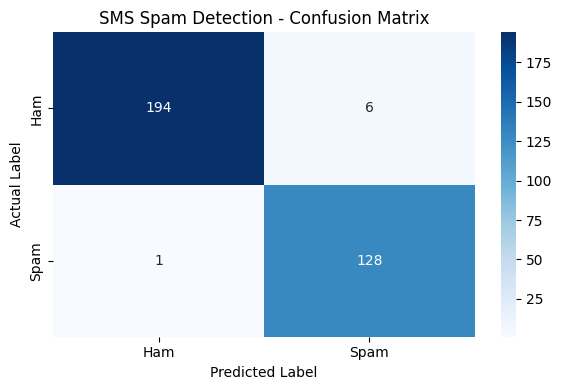

In [11]:

cm = confusion_matrix(y_test, y_pred, labels=[0, 1])

plt.figure(figsize=(6, 4))
sns.heatmap(
    cm,
    annot=True,
    fmt="d",
    cmap="Blues",
    xticklabels=["Ham", "Spam"],
    yticklabels=["Ham", "Spam"]
)

plt.title("SMS Spam Detection - Confusion Matrix")
plt.xlabel("Predicted Label")
plt.ylabel("Actual Label")
plt.tight_layout()
plt.show()


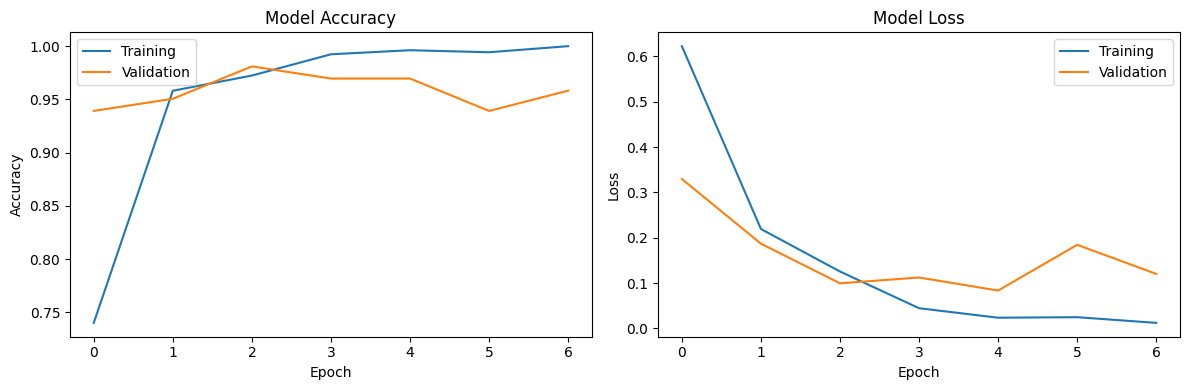

In [12]:

plt.figure(figsize=(12, 4))

plt.subplot(1, 2, 1)
plt.plot(history.history["accuracy"], label="Training")
plt.plot(history.history["val_accuracy"], label="Validation")
plt.title("Model Accuracy")
plt.xlabel("Epoch")
plt.ylabel("Accuracy")
plt.legend()

plt.subplot(1, 2, 2)
plt.plot(history.history["loss"], label="Training")
plt.plot(history.history["val_loss"], label="Validation")
plt.title("Model Loss")
plt.xlabel("Epoch")
plt.ylabel("Loss")
plt.legend()

plt.tight_layout()
plt.show()


In [13]:

new_messages = [
    "Congratulations! You have won a free prize. Claim it now!",
    "Hi, are we meeting at college tomorrow?",
    "URGENT! You have won a cash reward. Call now!",
    "Please send me the class notes when you are free.",
    "You have been selected for a free gift. Click the link now."
]

clean_messages = [clean_text(msg) for msg in new_messages]

new_sequences = tokenizer.texts_to_sequences(clean_messages)

new_padded = pad_sequences(
    new_sequences,
    maxlen=max_length,
    padding="post",
    truncating="post"
)

probabilities = model.predict(new_padded, verbose=0).ravel()

for message, prob in zip(new_messages, probabilities):
    result = "SPAM" if prob >= 0.5 else "HAM (Legitimate)"
    print("\nMessage:", message)
    print("Prediction:", result)
    print(f"Spam probability: {prob * 100:.2f}%")



Message: Congratulations! You have won a free prize. Claim it now!
Prediction: SPAM
Spam probability: 98.93%

Message: Hi, are we meeting at college tomorrow?
Prediction: HAM (Legitimate)
Spam probability: 0.38%

Message: URGENT! You have won a cash reward. Call now!
Prediction: SPAM
Spam probability: 98.61%

Message: Please send me the class notes when you are free.
Prediction: HAM (Legitimate)
Spam probability: 0.40%

Message: You have been selected for a free gift. Click the link now.
Prediction: SPAM
Spam probability: 97.76%


In [14]:

import pickle

model.save("sms_spam_lstm.keras")

with open("sms_tokenizer.pkl", "wb") as f:
    pickle.dump(tokenizer, f)

print("Model and tokenizer saved successfully!")

files.download("sms_spam_lstm.keras")
files.download("sms_tokenizer.pkl")


Model and tokenizer saved successfully!


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>